# Dados e Aprendizagem Automática 26/27
### Part IX
## **Autoencoder (MLP) using the Titanic Dataset**

#### Imports, installations and settings

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import torch

from torch.utils.data import TensorDataset, DataLoader
from torch.nn import Module, Linear, MSELoss
from torch.optim import Adam
from torch.optim.lr_scheduler import StepLR
from torchinfo import summary
from livelossplot import PlotLosses

from IPython.display import display

from sklearn.preprocessing import LabelEncoder, MinMaxScaler

%matplotlib inline

In [2]:
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cpu


In [4]:
PATH_TRAIN = '../daa_datasets_pl9/titanic_train_fe.csv'
PATH_TEST = '../daa_datasets_pl9/titanic_test_fe.csv'

BATCH_SIZE = 64

#### Titanic Dataset

Load the CSV - *Titanic*

In [5]:
train = pd.read_csv(PATH_TRAIN)
test = pd.read_csv(PATH_TEST)

In [6]:
print(f"train: {train.shape}")
print(f"test:  {test.shape}")

train: (891, 9)
test:  (418, 8)


In [7]:
train.head()

,PassengerId,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,1,0,3,1,22.0,1,0,7.2500,2
1,2,1,1,0,38.0,1,0,71.2833,0
2,3,1,3,0,26.0,0,0,7.9250,2
3,4,1,1,0,35.0,1,0,53.1000,2
4,5,0,3,1,35.0,0,0,8.0500,2


In [8]:
test.head()

,PassengerId,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,892,3,1,34.5,0,0,7.8292,1
1,893,3,0,47.0,1,0,7.0000,2
2,894,2,1,62.0,0,0,9.6875,1
3,895,3,1,27.0,0,0,8.6625,2
4,896,3,0,22.0,1,1,12.2875,2


Note: `titanic_test.csv` **does not have** the *Survived* column.

In [9]:
missing = pd.DataFrame({'train': train.isnull().sum(), 'test': test.isnull().sum()})
display(missing)

,train,test
Age,0,0.0
Embarked,0,0.0
Fare,0,0.0
Parch,0,0.0
PassengerId,0,0.0
Pclass,0,0.0
Sex,0,0.0
SibSp,0,0.0
Survived,0,NaN


In [10]:
print("Columns only in train:", set(train.columns) - set(test.columns))
print("Columns only in test: ", set(test.columns) - set(train.columns))

Columns only in train: {'Survived'}
Columns only in test:  set()


Distributions of *Age* and *Fare* in both files:

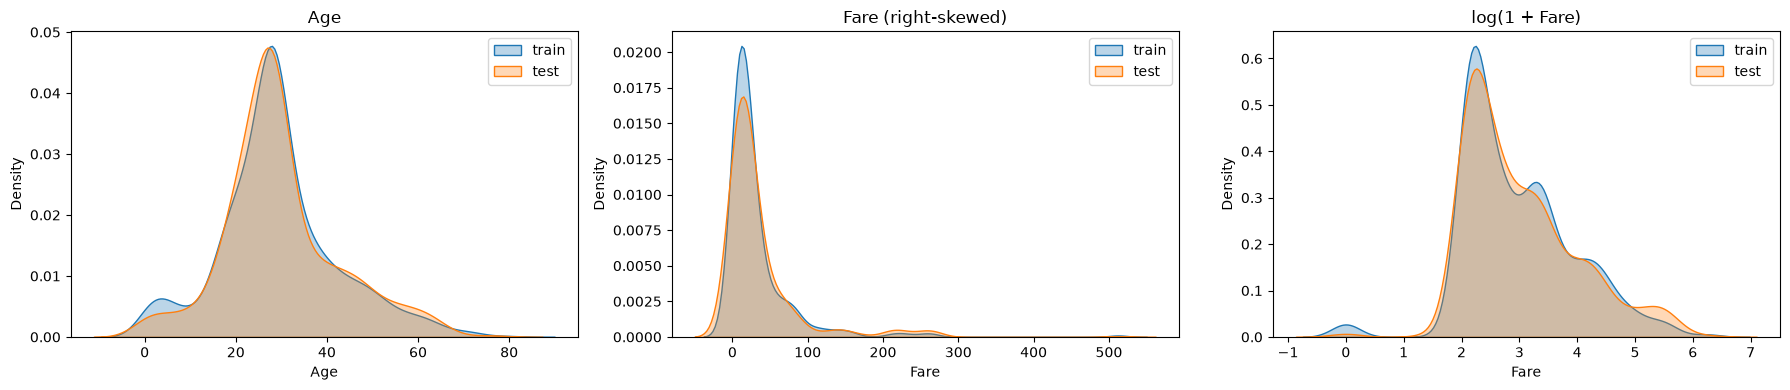

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

sns.kdeplot(train['Age'].dropna(), ax=axes[0], label='train', fill=True, alpha=0.3)
sns.kdeplot(test['Age'].dropna(), ax=axes[0], label='test', fill=True, alpha=0.3)
axes[0].set_title('Age')
axes[0].legend()

sns.kdeplot(train['Fare'].dropna(), ax=axes[1], label='train', fill=True, alpha=0.3)
sns.kdeplot(test['Fare'].dropna(), ax=axes[1], label='test', fill=True, alpha=0.3)
axes[1].set_title('Fare (right-skewed)')
axes[1].legend()

sns.kdeplot(np.log1p(train['Fare'].dropna()), ax=axes[2], label='train', fill=True, alpha=0.3)
sns.kdeplot(np.log1p(test['Fare'].dropna()), ax=axes[2], label='test', fill=True, alpha=0.3)
axes[2].set_title('log(1 + Fare)')
axes[2].legend()

plt.tight_layout()
plt.show()

#### Data preparation

An AE is **unsupervised**: the input is also the target, i.e. the network learns to reconstruct its own input through a small bottleneck, the *latent space*.

Choices to be made for the input of the AE:
- ***PassengerId*** is **not used**: it is just an identifier and it would only add noise;
- ***Survived*** is **not used**: it was the target and it does not exist in the test file. Keep it aside only to *colour* the latent space afterwards;
- ***Pclass*** is used as an input, and it is an ordinal feature. Keep it aside to color the latent space;
- ***Fare*** goes through `log(1 + Fare)` because it is very right-skewed;
- ***Embarked*** was **one-hot encoded** (C, Q, S): it was a nominal feature, which introduces a non-existent order;
- All the features should be scaled to [0, 1] with a `MinMaxScaler` **fitted on the train set** and applied to both files. The last layer of the decoder is a `sigmoid`, so the targets must be in the range [0, 1].

In [12]:
NUMERIC_FEATURES = ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']

In [13]:
def build_matrix(df):
    X = df[NUMERIC_FEATURES].copy().astype('float64')
    X['Fare'] = np.log1p(X['Fare'])
    return X

In [14]:
X_train_df = build_matrix(train)
X_test_df = build_matrix(test)

In [15]:
FEATURE_NAMES = list(X_train_df.columns)
print(FEATURE_NAMES)

['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']


In [16]:
FEATURE_NAMES2 = list(X_test_df.columns)
print(FEATURE_NAMES2)

['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']


In [17]:
X_train_df

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,3.0,1.0,22.0,1.0,0.0,2.110213,2.0
1,1.0,0.0,38.0,1.0,0.0,4.280593,0.0
2,3.0,0.0,26.0,0.0,0.0,2.188856,2.0
3,1.0,0.0,35.0,1.0,0.0,3.990834,2.0
4,3.0,1.0,35.0,0.0,0.0,2.202765,2.0
...,...,...,...,...,...,...,...
886,2.0,1.0,27.0,0.0,0.0,2.639057,2.0
887,1.0,0.0,19.0,0.0,0.0,3.433987,2.0
888,3.0,0.0,28.0,1.0,2.0,3.196630,2.0
889,1.0,1.0,26.0,0.0,0.0,3.433987,0.0


In [18]:
X_test_df

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,3.0,1.0,34.5,0.0,0.0,2.178064,1.0
1,3.0,0.0,47.0,1.0,0.0,2.079442,2.0
2,2.0,1.0,62.0,0.0,0.0,2.369075,1.0
3,3.0,1.0,27.0,0.0,0.0,2.268252,2.0
4,3.0,0.0,22.0,1.0,1.0,2.586824,2.0
...,...,...,...,...,...,...,...
413,3.0,1.0,28.0,0.0,0.0,2.202765,2.0
414,1.0,0.0,39.0,0.0,0.0,4.699571,0.0
415,3.0,1.0,38.5,0.0,0.0,2.110213,2.0
416,3.0,1.0,28.0,0.0,0.0,2.202765,2.0


In [19]:
#fit the scaler on train only
scaler = MinMaxScaler()
scaler.fit(X_train_df)

,"feature_range feature_range: tuple (min, max), default=(0, 1)Desired range of transformed data.","(0, ...)"
,"copy copy: bool, default=TrueSet to False to perform inplace row normalization and avoid acopy (if the input is already a numpy array).",True
,"clip clip: bool, default=FalseSet to True to clip transformed values of held-out data toprovided `feature_range`.Since this parameter will clip values, `inverse_transform` may notbe able to restore the original data... note:: Setting `clip=True` does not prevent feature drift (a distribution shift between training and test data). The transformed values are clipped to the `feature_range`, which helps avoid unintended behavior in models sensitive to out-of-range inputs (e.g. linear models). Use with care, as clipping can distort the distribution of test data... versionadded:: 0.24",False
Name,Type,Value
"data_max_ data_max_: ndarray of shape (n_features,)Per feature maximum seen in the data.. versionadded:: 0.17 *data_max_*","ndarray[float64](7,)","[ 3. , 1. ,80. ,..., 6. , 6.24, 2. ]"
"data_min_ data_min_: ndarray of shape (n_features,)Per feature minimum seen in the data.. versionadded:: 0.17 *data_min_*","ndarray[float64](7,)","[1. ,0. ,0.42,...,0. ,0. ,0. ]"
"data_range_ data_range_: ndarray of shape (n_features,)Per feature range ``(data_max_ - data_min_)`` seen in the data.. versionadded:: 0.17 *data_range_*","ndarray[float64](7,)","[ 2. , 1. ,79.58,..., 6. , 6.24, 2. ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](7,)","['Pclass','Sex','Age',...,'Parch','Fare','Embarked']"
"min_ min_: ndarray of shape (n_features,)Per feature adjustment for minimum. Equivalent to``min - X.min(axis=0) * self.scale_``","ndarray[float64](7,)","[-0.5 , 0. ,-0.01,..., 0. , 0. , 0. ]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,7
"n_samples_seen_ n_samples_seen_: intThe number of samples processed by the estimator.It will be reset on new calls to fit, but increments across``partial_fit`` calls.",int,891


In [20]:
X_train = scaler.transform(X_train_df)
X_test = scaler.transform(X_test_df)

In [21]:
X_train

array([[1.        , 1.        , 0.27117366, ..., 0.        , 0.33812548,
        1.        ],
       [0.        , 0.        , 0.4722292 , ..., 0.        , 0.68589165,
        0.        ],
       [1.        , 0.        , 0.32143755, ..., 0.        , 0.3507267 ,
        1.        ],
       ...,
       [1.        , 0.        , 0.34656949, ..., 0.33333333, 0.51220518,
        1.        ],
       [0.        , 1.        , 0.32143755, ..., 0.        , 0.55023757,
        0.        ],
       [1.        , 1.        , 0.39683338, ..., 0.        , 0.34755367,
        0.5       ]], shape=(891, 7))

In [22]:
X_test

array([[1.        , 1.        , 0.4282483 , ..., 0.        , 0.34899748,
        0.5       ],
       [1.        , 0.        , 0.58532295, ..., 0.        , 0.33319485,
        1.        ],
       [0.5       , 1.        , 0.77381252, ..., 0.        , 0.37960362,
        0.5       ],
       ...,
       [1.        , 1.        , 0.47851219, ..., 0.        , 0.33812548,
        1.        ],
       [1.        , 1.        , 0.34656949, ..., 0.        , 0.35295528,
        1.        ],
       [1.        , 1.        , 0.34656949, ..., 0.16666667, 0.50488609,
        0.        ]], shape=(418, 7))

In [23]:
print(f"test values outside [0,1] before clipping: {((X_test < 0) | (X_test > 1)).sum()}")
X_test = np.clip(X_test, 0, 1)

test values outside [0,1] before clipping: 4


In [24]:
X_train = X_train.astype('float32')
X_test = X_test.astype('float32')
print(X_train.shape, X_test.shape)

(891, 7) (418, 7)


##### Data loaders

Create the loaders with batches for training and the loaders with all the cases in a single batch to analyze the latent space. 
The second element of each case is the *Pclass*, which exists in both files; it is **not used** for training, bur only for plotting.

In [25]:
pclass_train = train['Pclass'].values.astype('int64')
pclass_test = test['Pclass'].values.astype('int64')

In [26]:
def prepare_data(X_train, X_test, pclass_train, pclass_test):
    train = TensorDataset(torch.from_numpy(X_train), torch.from_numpy(pclass_train))
    test = TensorDataset(torch.from_numpy(X_test), torch.from_numpy(pclass_test))
    g = torch.Generator().manual_seed(SEED)
    train_dl = DataLoader(train, batch_size=BATCH_SIZE, shuffle=True, generator=g)
    test_dl = DataLoader(test, batch_size=BATCH_SIZE, shuffle=False)
    train_dl_all = DataLoader(train, batch_size=len(train), shuffle=False)
    test_dl_all = DataLoader(test, batch_size=len(test), shuffle=False)
    return train_dl, test_dl, train_dl_all, test_dl_all

In [27]:
train_dl, test_dl, train_dl_all, test_dl_all = prepare_data(X_train, X_test, pclass_train, pclass_test)

In [28]:
def visualize_dataset(train_dl, test_dl):
    print(f"Number of train cases: {len(train_dl.dataset)}")
    print(f"Number of test cases:  {len(test_dl.dataset)}")
    x, y = next(iter(train_dl))
    print(f"Shape of a train batch, input: {x.shape}, pclass: {y.shape}")
    x, y = next(iter(test_dl))
    print(f"Shape of a test batch,  input: {x.shape}, pclass: {y.shape}")

In [29]:
visualize_dataset(train_dl, test_dl)

Number of train cases: 891
Number of test cases:  418
Shape of a train batch, input: torch.Size([64, 7]), pclass: torch.Size([64])
Shape of a test batch,  input: torch.Size([64, 7]), pclass: torch.Size([64])


In [30]:
display(pd.DataFrame(X_train, columns=FEATURE_NAMES).describe().loc[['min', 'mean', 'max']].round(3))

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
min,0.000,0.000,0.000,0.000,0.000,0.000,0.000
mean,0.654,0.648,0.364,0.065,0.064,0.475,0.768
max,1.000,1.000,1.000,1.000,1.000,1.000,1.000


#### Autoencoder MLP

- **Encoder**: 9 → 16 → 8 → **2** (latent space)
- **Decoder**: 2 → 8 → 16 → 9
- **Activation functions**: ReLU in the hidden layers, `sigmoid` in the output of the decoder (outputs in [0, 1])
- **Latent space with 2 dimensions** so it can be plotted directly
- **Loss**: MSELoss (the features are a mix of continuous and binary values in [0, 1])
- **Optimizer**: Adam with a `StepLR` scheduler

In [31]:
class AE_MLP_Titanic(Module):
    def __init__(self, x_dim=9, h_dim1=16, h_dim2=8, ls_dim=2):
        super(AE_MLP_Titanic, self).__init__()
        self.x_dim = x_dim
        
        self.fc1 = Linear(x_dim, h_dim1)
        self.fc2 = Linear(h_dim1, h_dim2)
        self.fc3 = Linear(h_dim2, ls_dim)
        
        self.fc4 = Linear(ls_dim, h_dim2)
        self.fc5 = Linear(h_dim2, h_dim1)
        self.fc6 = Linear(h_dim1, x_dim)

    def encoder(self, x):
        x = self.fc1(x).relu()
        x = self.fc2(x).relu()
        x = self.fc3(x)
        return x

    def decoder(self, z):
        z = self.fc4(z).relu()
        z = self.fc5(z).relu()
        z = self.fc6(z).sigmoid()
        return z

    def forward(self, x):
        x = x.view(-1, self.x_dim)
        ls = self.encoder(x)
        z = self.decoder(ls)
        return z, ls

In [32]:
model = AE_MLP_Titanic(x_dim=X_train.shape[1], h_dim1=16, h_dim2=8, ls_dim=2)

In [33]:
print(summary(model, input_size=(BATCH_SIZE, X_train.shape[1]), verbose=0))
model.to(device)

Layer (type:depth-idx)                   Output Shape              Param #
AE_MLP_Titanic                           [64, 7]                   --
├─Linear: 1-1                            [64, 16]                  128
├─Linear: 1-2                            [64, 8]                   136
├─Linear: 1-3                            [64, 2]                   18
├─Linear: 1-4                            [64, 8]                   24
├─Linear: 1-5                            [64, 16]                  144
├─Linear: 1-6                            [64, 7]                   119
Total params: 569
Trainable params: 569
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 0.04
Input size (MB): 0.00
Forward/backward pass size (MB): 0.03
Params size (MB): 0.00
Estimated Total Size (MB): 0.03


AE_MLP_Titanic(
  (fc1): Linear(in_features=7, out_features=16, bias=True)
  (fc2): Linear(in_features=16, out_features=8, bias=True)
  (fc3): Linear(in_features=8, out_features=2, bias=True)
  (fc4): Linear(in_features=2, out_features=8, bias=True)
  (fc5): Linear(in_features=8, out_features=16, bias=True)
  (fc6): Linear(in_features=16, out_features=7, bias=True)
)

#### Train the model

The test set is used here as the validation set: since the AE does not need labels, the reconstruction loss can be computed directly on the test file.

In [34]:
EPOCHS = 150
LEARNING_RATE = 1e-3

In [35]:
def train_model(file, train_dl, test_dl, model, loss_function, optimizer, scheduler, epochs):
    #to visualize the training process
    liveloss = PlotLosses()
    for epoch in range(epochs):
        logs = {}
        model.train()
        running_loss = 0.0
        for inputs, _ in train_dl:
            inputs = inputs.to(device)
            outputs, _ = model(inputs)
            loss = loss_function(outputs, inputs)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * inputs.size(0)
        logs['loss'] = running_loss / len(train_dl.dataset)
        scheduler.step()
        logs['lr'] = scheduler.get_last_lr()[0]

        model.eval()
        running_loss = 0.0
        with torch.no_grad():
            for inputs, _ in test_dl:
                inputs = inputs.to(device)
                outputs, _ = model(inputs)
                loss = loss_function(outputs, inputs)
                running_loss += loss.item() * inputs.size(0)
        logs['val_loss'] = running_loss / len(test_dl.dataset)
        liveloss.update(logs)
        liveloss.send()
    torch.save(model.state_dict(), file)

In [36]:
loss_function = MSELoss()
optimizer = Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-5)
scheduler = StepLR(optimizer, step_size=10, gamma=0.95)

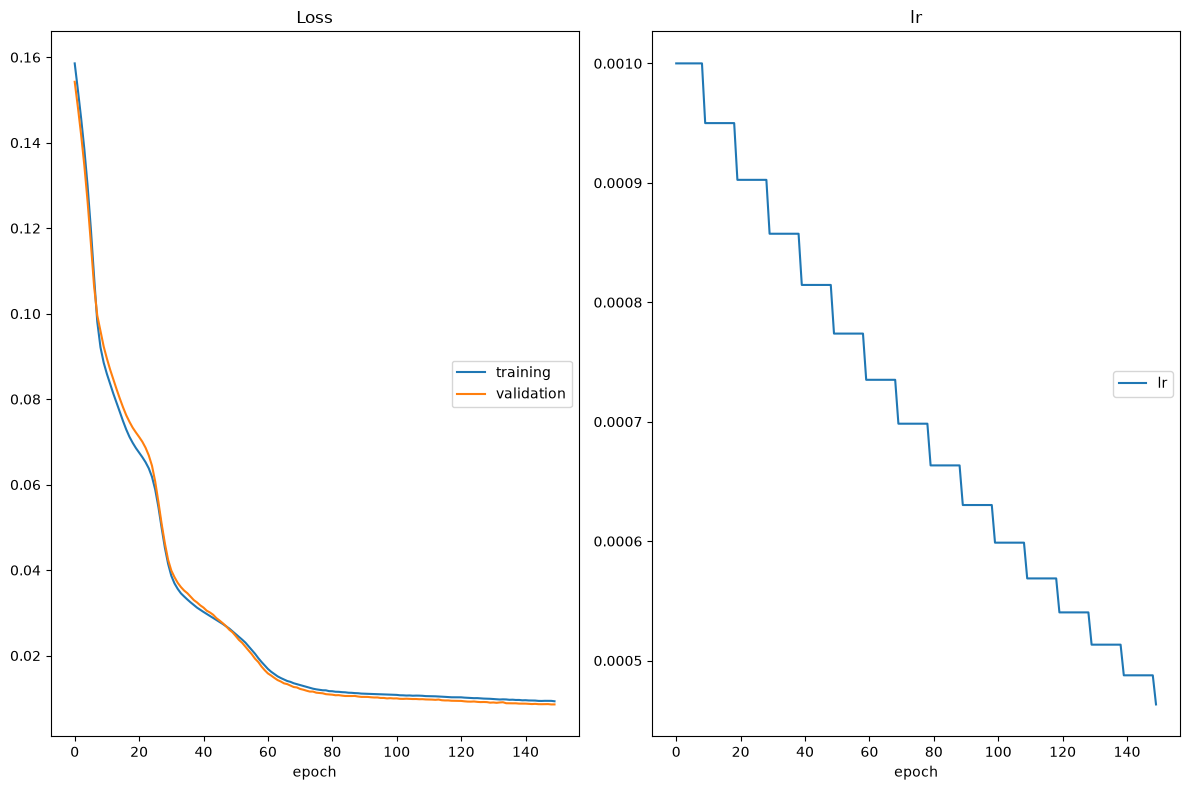

Loss
	training         	 (min:    0.009, max:    0.159, cur:    0.009)
	validation       	 (min:    0.009, max:    0.154, cur:    0.009)
lr
	lr               	 (min:    0.000, max:    0.001, cur:    0.000)
Time spent: 15.1 seconds


In [37]:
starttime = time.perf_counter()
train_model('AE_MLP_Titanic.pth', train_dl, test_dl, model, loss_function, optimizer, scheduler, EPOCHS)
endtime = time.perf_counter()
print(f"Time spent: {endtime - starttime:.1f} seconds")

#### Evaluate and use the autoencoder

In [38]:
model = AE_MLP_Titanic(x_dim=X_train.shape[1], h_dim1=16, h_dim2=8, ls_dim=2)
model.load_state_dict(torch.load('AE_MLP_Titanic.pth', map_location=device))
model.to(device)
model.eval()

AE_MLP_Titanic(
  (fc1): Linear(in_features=7, out_features=16, bias=True)
  (fc2): Linear(in_features=16, out_features=8, bias=True)
  (fc3): Linear(in_features=8, out_features=2, bias=True)
  (fc4): Linear(in_features=2, out_features=8, bias=True)
  (fc5): Linear(in_features=8, out_features=16, bias=True)
  (fc6): Linear(in_features=16, out_features=7, bias=True)
)

#### Reconstruction

Load the saved model and reconstruct the train and test files.

In [39]:
def reconstruct(model, dl_all):
    inputs, pclass = next(iter(dl_all))
    with torch.no_grad():
        outputs, ls = model(inputs.to(device))
    return inputs.numpy(), outputs.cpu().numpy(), ls.cpu().numpy(), pclass.numpy()

In [40]:
x_tr, rec_tr, ls_tr, pc_tr = reconstruct(model, train_dl_all)
x_te, rec_te, ls_te, pc_te = reconstruct(model, test_dl_all)

In [41]:
print(f"Reconstruction MSE - train: {np.mean((x_tr - rec_tr) ** 2):.5f}")
print(f"Reconstruction MSE - test:  {np.mean((x_te - rec_te) ** 2):.5f}")

Reconstruction MSE - train: 0.00925
Reconstruction MSE - test:  0.00858


Reconstruction error per feature (test set)

The features that need more information to be reconstructed from only 2 numbers show a higher error:

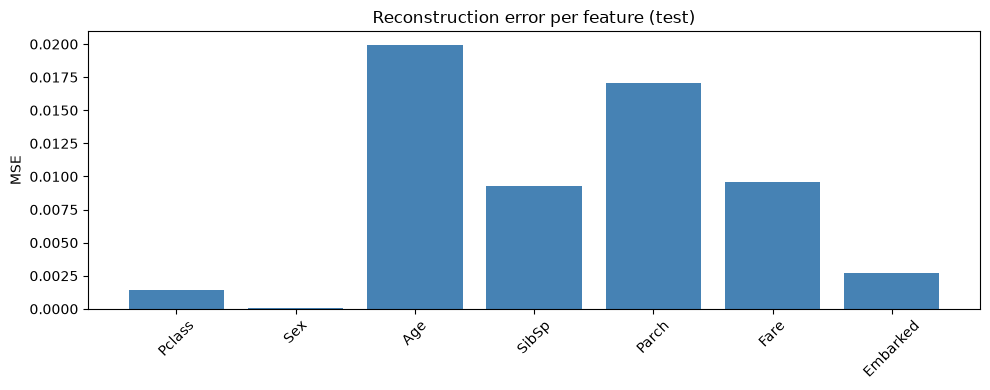

In [42]:
err_feat = ((x_te - rec_te) ** 2).mean(axis=0)
plt.figure(figsize=(10, 4))
plt.bar(FEATURE_NAMES, err_feat, color='steelblue')
plt.xticks(rotation=45)
plt.ylabel('MSE')
plt.title('Reconstruction error per feature (test)')
plt.tight_layout()
plt.show()

Compare the original and the reconstructed passengers in their original units (inverse scaling, using `expm1` for *Fare*):

In [43]:
def to_original_units(x_scaled):
    x = scaler.inverse_transform(x_scaled)
    out = pd.DataFrame(x, columns=FEATURE_NAMES)
    out['Fare'] = np.expm1(out['Fare'])
    return out

In [44]:
SHOW = ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']

original = test[SHOW].copy()
reconstructed = to_original_units(rec_te)[SHOW]

idx = list(range(8))
comparison = pd.concat([original.iloc[idx].reset_index(drop=True).round(2),
                        reconstructed.iloc[idx].reset_index(drop=True).round(2)],
                       axis=1, keys=['original', 'reconstructed'])
display(comparison)

original                                       reconstructed       \
    Pclass Sex   Age SibSp Parch   Fare Embarked        Pclass  Sex   
0        3   1  34.5     0     0   7.83        1          2.98  1.0   
1        3   0  47.0     1     0   7.00        2          2.90  0.0   
2        2   1  62.0     0     0   9.69        1          1.99  1.0   
3        3   1  27.0     0     0   8.66        2          2.99  1.0   
4        3   0  22.0     1     1  12.29        2          2.90  0.0   
5        3   1  14.0     0     0   9.22        2          2.99  1.0   
6        3   0  30.0     0     0   7.63        1          2.96  0.0   
7        2   1  26.0     1     1  29.00        2          1.95  1.0   

                                              
         Age SibSp Parch       Fare Embarked  
0  25.820000  0.29  0.13  11.760000     1.01  
1  23.610001  0.63  0.68  14.590000     2.00  
2  32.290001  0.39  0.27  23.379999     1.48  
3  25.379999  0.68  0.21   8.730000     1.94  
4  23.459999  0.83  0.80  14.780000     2.00  
5  24.760000  0.61  0.19   8.330000     1.91  
6  22.180000  0.02  0.06   8.880000     0.94  
7  32.990002  0.74  0.39  16.889999     1.99

#### Latent space

Each passenger is now described by only 2 numbers. If the AE learned something useful, **passengers with similar characteristics should be close to each other**.
Color the points using information the AE **never saw during training** (*Survived* and *Pclass*), projecting the test passengers into the same space.

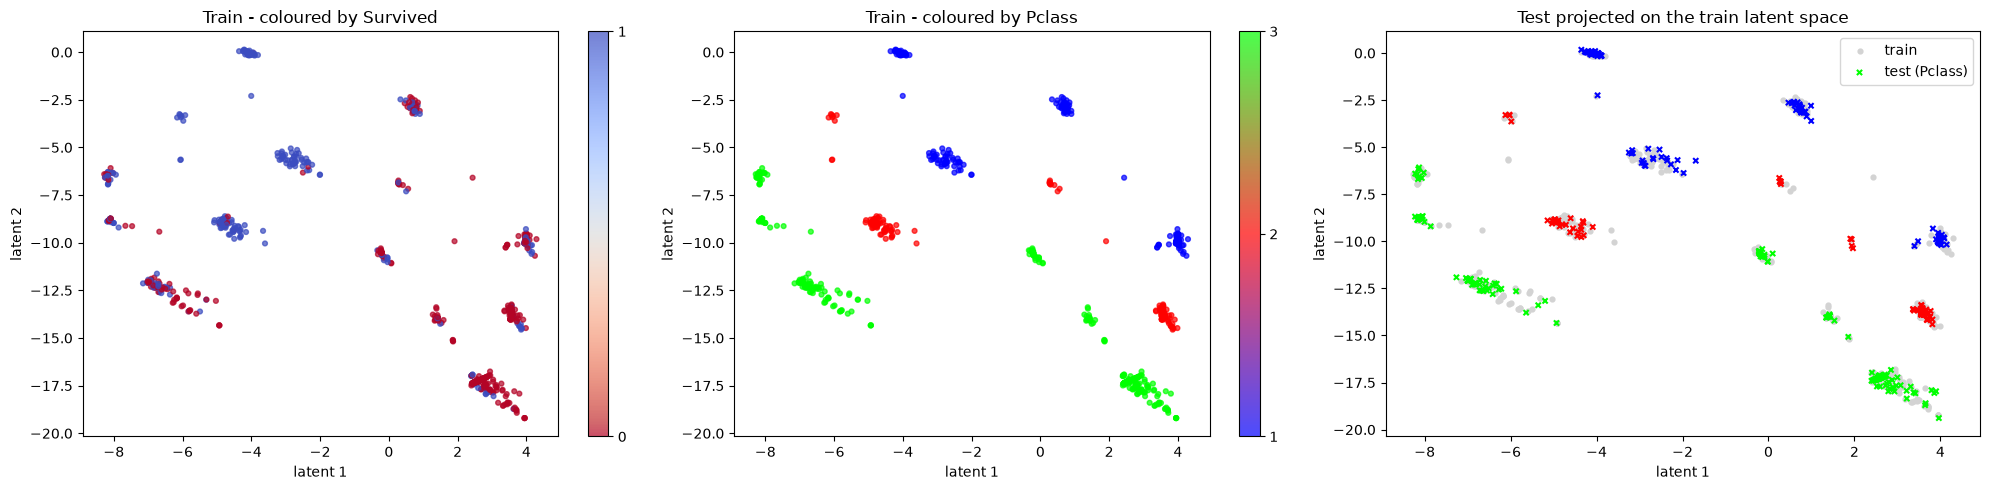

In [45]:
survived_tr = train['Survived'].values

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

sc = axes[0].scatter(ls_tr[:, 0], ls_tr[:, 1], c=survived_tr, cmap='coolwarm_r', s=12, alpha=0.7)
axes[0].set_title('Train - coloured by Survived')
plt.colorbar(sc, ax=axes[0], ticks=[0, 1])

sc = axes[1].scatter(ls_tr[:, 0], ls_tr[:, 1], c=pc_tr, cmap='brg', s=12, alpha=0.7)
axes[1].set_title('Train - coloured by Pclass')
plt.colorbar(sc, ax=axes[1], ticks=[1, 2, 3])

axes[2].scatter(ls_tr[:, 0], ls_tr[:, 1], c='lightgrey', s=12, label='train')
sc = axes[2].scatter(ls_te[:, 0], ls_te[:, 1], c=pc_te, cmap='brg', s=14, marker='x', label='test (Pclass)')
axes[2].set_title('Test projected on the train latent space')
axes[2].legend()

for ax in axes:
    ax.set_xlabel('latent 1')
    ax.set_ylabel('latent 2')
plt.tight_layout()
plt.show()

#### Generate passengers from the latent space

Feed the **decoder** with a point in the latent space.

Since the latent space is organized in small clusters with empty gaps between them, the mean of a whole *Pclass* group usually falls in a gap and **yields a meaningless passenger upon decoding**. Instead, for each *Pclass*, use the train passenger whose **latent point is closest to the center of its group**.

In [46]:
def generate_from_latent(model, ls):
    ls = torch.tensor(np.array(ls), dtype=torch.float32).to(device)
    with torch.no_grad():
        out = model.decoder(ls)
    return out.cpu().numpy()

In [47]:
representatives = []
for c in [1, 2, 3]:
    group = ls_tr[pc_tr == c]
    centre = group.mean(axis=0)
    representatives.append(group[np.argmin(((group - centre) ** 2).sum(axis=1))])
representatives = np.array(representatives)

In [48]:
generated = to_original_units(generate_from_latent(model, representatives))[SHOW].round(2)
generated.index = [f'Pclass {c} (ls={np.round(representatives[i], 2)})' for i, c in enumerate([1, 2, 3])]
display(generated)

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
Pclass 1 (ls=[-2. -6.43]),1.22,0.08,35.930000,1.16,1.07,45.18,1.81
Pclass 2 (ls=[ 1.91 -9.92]),2.02,1.00,32.169998,0.38,0.27,23.18,1.46
Pclass 3 (ls=[ 1.33 -14.09]),2.98,1.00,25.320000,0.27,0.12,11.21,0.90


Dividing the latent space into 6 points between the representative of *Pclass 1* and the representative of *Pclass 3*, the decoded passenger changes gradually:

In [49]:
steps = np.linspace(0, 1, 6).reshape(-1, 1)
path = representatives[0] + steps * (representatives[2] - representatives[0])
walk = to_original_units(generate_from_latent(model, path))[SHOW].round(2)
walk.index = [f'ls={np.round(p, 2)}' for p in path]
display(walk)

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
ls=[-2. -6.43],1.22,0.08,35.930000,1.16,1.07,45.18,1.81
ls=[-1.33 -7.96],2.02,0.94,33.759998,0.60,0.48,25.93,1.14
ls=[-0.67 -9.49],2.79,1.00,31.629999,0.30,0.20,14.54,0.31
ls=[ -0. -11.03],2.96,1.00,28.299999,0.15,0.09,9.63,0.07
ls=[ 0.67 -12.56],2.98,1.00,25.049999,0.16,0.09,12.48,0.20
ls=[ 1.33 -14.09],2.98,1.00,25.320000,0.27,0.12,11.21,0.90


#### Anomaly detection with the reconstruction error

Passengers that are **unusual**, compared to what the AE saw in the training set,  are reconstructed **more poorly**.

The 5 test passengers with the highest reconstruction error:

In [50]:
err_sample = ((x_te - rec_te) ** 2).mean(axis=1)

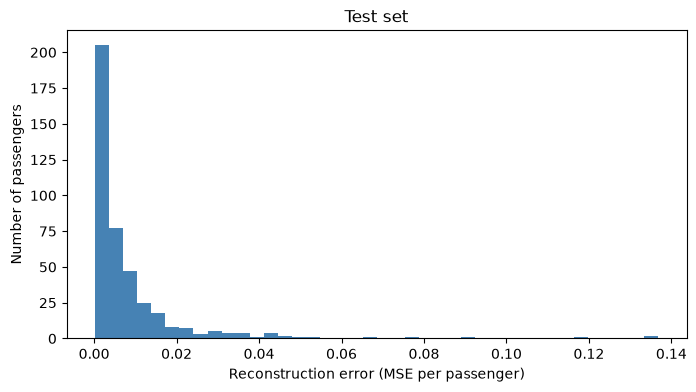

In [51]:
plt.figure(figsize=(8, 4))
plt.hist(err_sample, bins=40, color='steelblue')
plt.xlabel('Reconstruction error (MSE per passenger)')
plt.ylabel('Number of passengers')
plt.title('Test set')
plt.show()

In [52]:
top = np.argsort(err_sample)[::-1][:5]
display(test.iloc[top][['PassengerId', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']]
        .assign(reconstruction_error=err_sample[top].round(4)))

,PassengerId,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,reconstruction_error
342,1234,3,1,28.0,1,9,69.5500,2,0.1369
139,1031,3,1,40.0,1,6,46.9000,2,0.1348
360,1252,3,1,14.5,8,2,69.5500,2,0.1177
174,1066,3,1,40.0,1,5,31.3875,2,0.0910
365,1257,3,0,28.0,1,9,69.5500,2,0.0760


#### Conclusões
- O AE comprime cada passageiro de 7 variáveis para **2 números**, e mesmo assim reconstrói-o com um erro baixo (MSE ≈ 0.009 no treino e ≈ 0.009 no teste, nos slides). Como os dois valores são próximos, **não há overfitting**.
- As variáveis com mais erro de reconstrução são as que precisam de mais informação para ser reconstruídas a partir de só 2 números (por exemplo `Age` e `Fare`). As variáveis binárias ou com poucos valores, como `Sex` e `Pclass`, são reconstruídas quase na perfeição.
- **O espaço latente organiza os passageiros por classe e por sobrevivência**, apesar de o AE nunca ter visto essas labels. Os passageiros do teste caem nas mesmas regiões que os do treino.
- O **decoder funciona como gerador**: ao percorrer o espaço latente entre o representante da 1.ª classe e o da 3.ª, o passageiro gerado muda de forma gradual (tarifa, classe, idade).
- **Deteção de anomalias:** os passageiros com maior erro de reconstrução têm combinações pouco habituais no treino (por exemplo, tarifas muito altas ou famílias muito grandes).